# Fig. 2b: Model fits to the monkeys' choices

[AI generated summary] Cross-validated likelihood per trial (LPT) of the models fitted to the choices of each monkey (WSLS, standard and inferential RL with and without stickiness, foraging).

**How to run:** run all cells. Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/behav_modeling/fitting` (see the README). To recompute them, run in this folder: `python run_model_fitting.py` (10-fold cross-validated maximum likelihood fits; several hours).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from popy.config import COLORS
from helpers import load_fitting_results

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def plot_res(res_all, paper_format=False):
    # Set font size and figure size
    if paper_format:
        plt.rcParams.update({'font.size': 8})
        w, h = 4, 4
    else:
        plt.rcParams.update({'font.size': 8})
        w, h = ((12/5)/3)*(len(res_all)/2), 5/1

    # Define the modes and figure
    modes = ['LPT_CV']
    fig, axes = plt.subplots(2, 1, figsize=(w/2.54, h/2.54), gridspec_kw={'hspace': 0.3})

    # Get unique values
    models = res_all.loc[res_all['monkey'] != 'yu_DCZ', 'Model'].unique()
    monkeys = res_all.loc[res_all['monkey'] != 'yu_DCZ', 'monkey'].unique()

    # Iterate over the modes and plot
    for mode_idx, mode in enumerate(modes):
        # Set up positions
        x = np.arange(len(models))
        width = 0.65  # Width of bars

        for i, monkey in enumerate(monkeys):
            ax = axes[i]  # Use separate subplot for each monkey
            
            data = res_all.loc[(res_all['monkey'] == monkey) & (res_all['monkey'] != 'yu_DCZ')]
            values = [data.loc[data['Model'] == model, mode].iloc[0] if len(data.loc[data['Model'] == model]) > 0 else 0 for model in models]
            
            # Create bars with model-based coloring
            for j, (model, value) in enumerate(zip(models, values)):
                hatch = None
                if model.split()[0] == 'Standard':
                    # replace  what comes after with RL
                    color = COLORS['Standard RL']
                    if (not model == 'Standard RL - stickiness' and not paper_format) or (paper_format and not model == 'Standard RL'):
                        hatch = '///'  # Dashed filling pattern
                elif model.split()[0] == 'Inferential':
                    color = COLORS['Inferential RL']
                    if (not model == 'Inferential RL - stickiness' and not paper_format) or (paper_format and not model == 'Inferential RL'):
                        hatch = '///'  # Dashed filling pattern
                elif model.split()[0] == 'Foraging':
                    color = COLORS['Foraging']
                    if not len(model.split(" ")) == 1:
                        hatch = '///'  # Dashed filling pattern
                else:
                    color = COLORS.get(model, 'grey')
                    hatch = None
                alpha = 0.8
                
                
                bar = ax.bar(x[j], value, width, 
                    color=color, hatch=hatch,
                    edgecolor='black', linewidth=0.5, alpha=alpha)
                
                # Set hatch color to grey for RL-s models
                if model.split()[-1] == 'RL-s':
                    import matplotlib as mpl
                    mpl.rcParams['hatch.color'] = 'grey'
            
            
            for model, value in zip(models, values):
                print(f"{mode}: {monkey} {model}: {value:.2f}")

            # add monkey name (capitalized) as title, y axis a bit lower
            ax.set_title(monkey.upper(), fontsize=10, y=.85)

            # Configure axes
            ax.set_ylim(0.3, 0.85)
            ax.set_yticks(np.arange(0.3, 0.9, 0.2))
            ax.set_ylabel('LPT', fontsize=8)
            
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

            ax.grid(axis='y', linestyle='dotted', alpha=0.5, zorder=0)

            # Only add x-axis labels to bottom plot
            if i == len(monkeys) - 1:  # Bottom plot
                ax.set_xticks(x)
                if paper_format:
                    ax.set_xticklabels(models, rotation=45, horizontalalignment='right')
                else:
                    ax.set_xticklabels(models, rotation=-90, horizontalalignment='center')
            else:  # Top plot
                ax.set_xticks(x)
                ax.set_xticklabels([])  # Remove x-axis labels from top plot

    return fig, axes

---
# Load results

In [4]:
res_all = load_fitting_results()

res_all = res_all.sort_values('Model')
res_all

,Model,epsilon,alpha,alpha_unchosen,beta,V0,forgetting_rate,forgetting_threshold,stickiness_bias,b2,...,BIC_std,LPT_CV,LPT_std,LL_best,BIC_best,LPT_best,Reward rate,Proba best,alpha_threshold,monkey
15,Foraging,NaN,0.403461,NaN,10.743618,0.121124,NaN,NaN,NaN,NaN,...,117.058119,0.787503,0.017931,-5666.449537,11363.138951,0.788607,0.54781,0.71869,NaN,ka
31,Foraging,NaN,0.301837,NaN,6.968843,0.178251,NaN,NaN,NaN,NaN,...,306.549987,0.595746,0.039285,-7830.636466,15690.151188,0.596484,0.51466,0.63288,NaN,po
4,Foraging - abandoned bias,NaN,0.379934,NaN,11.100396,0.131046,NaN,NaN,NaN,NaN,...,117.667341,0.786902,0.017939,-5676.827432,11404.054657,0.788264,0.54779,0.72091,NaN,ka
27,Foraging - abandoned bias,NaN,0.317311,NaN,5.928644,0.108388,NaN,NaN,NaN,NaN,...,308.388603,0.595720,0.039265,-7866.166657,15780.463743,0.595087,0.51774,0.63436,NaN,po
23,Foraging - abandoned bias + spatial bias,NaN,0.316672,NaN,6.532717,0.158220,NaN,NaN,NaN,0.691090,...,305.438814,0.595455,0.038955,-7834.315177,15726.386869,0.596339,0.50416,0.60011,NaN,po
9,Foraging - abandoned bias + spatial bias,NaN,0.405176,NaN,10.967922,0.127105,NaN,NaN,NaN,-3.607682,...,121.052875,0.786089,0.018646,-5668.390823,11397.261399,0.788543,0.49657,0.57521,NaN,ka
26,Foraging - adaptive threshold,NaN,0.335737,NaN,6.773412,0.158426,NaN,NaN,NaN,NaN,...,300.865560,0.596115,0.038498,-7845.019814,15728.543972,0.595918,0.52410,0.65009,0.00000,po
10,Foraging - adaptive threshold,NaN,0.457614,NaN,9.094214,0.050000,NaN,NaN,NaN,NaN,...,118.558237,0.786237,0.017479,-5726.348352,11493.016539,0.786630,0.54296,0.70340,0.00036,ka
3,Foraging - no reset,NaN,0.430530,NaN,11.014925,0.130596,NaN,NaN,NaN,NaN,...,127.347576,0.783186,0.020132,-5802.958057,11636.155990,0.784108,0.54748,0.71576,NaN,ka
22,Foraging - no reset,NaN,0.438418,NaN,5.432612,0.167679,NaN,NaN,NaN,NaN,...,321.866504,0.579654,0.040132,-8253.556660,16535.991577,0.580068,0.49715,0.57755,NaN,po


---
# Fig. 2b

LPT_CV: ka WSLS: 0.40
LPT_CV: ka Standard RL-noS: 0.68
LPT_CV: ka Inferential RL-noS: 0.58
LPT_CV: ka Standard RL: 0.74
LPT_CV: ka Inferential RL: 0.75
LPT_CV: ka Foraging: 0.79
LPT_CV: po WSLS: 0.39
LPT_CV: po Standard RL-noS: 0.47
LPT_CV: po Inferential RL-noS: 0.44
LPT_CV: po Standard RL: 0.52
LPT_CV: po Inferential RL: 0.56
LPT_CV: po Foraging: 0.60


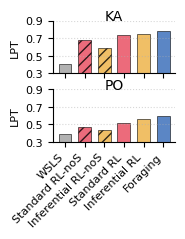

In [5]:
models_to_show = {
    'WSLS': 'WSLS',
    'Standard RL': 'Standard RL-noS',
    'Inferential RL': 'Inferential RL-noS',
    'Standard RL - stickiness': 'Standard RL',
    'Inferential RL - stickiness': 'Inferential RL',
    'Foraging': 'Foraging'
}

res_all_temp = res_all[res_all['Model'].isin(models_to_show.keys())].copy()
res_all_temp['Model'] = res_all_temp['Model'].map(models_to_show)
# sort in the order of models_to_show values, KA first and PO second
res_all_temp['Model'] = pd.Categorical(res_all_temp['Model'], categories=models_to_show.values(), ordered=True)
res_all_temp['monkey'] = pd.Categorical(res_all_temp['monkey'], categories=['ka', 'po'], ordered=True)
res_all_temp = res_all_temp.sort_values(['Model', 'monkey'])

fig, ax = plot_res(res_all_temp, paper_format=True)

# Adjust layout and save as SVG if needed
#plt.tight_layout()
# Uncomment the following line to save the figure
plt.savefig(os.path.join(FIGS_PATH, 'fig2b_lpt.svg'), dpi=300, bbox_inches='tight', transparent=False)

plt.show()

In [6]:
# Export source data (Figure 2b)
from popy.source_data import export_source_data

# bar heights: cross-validated LPT of each model, for KA (top plot) and PO (bottom plot), as selected in plot_res
models = res_all_temp['Model'].unique()
lpt = pd.DataFrame({'Model': [str(model) for model in models]})
for monkey in ['ka', 'po']:
    data = res_all_temp[res_all_temp['monkey'] == monkey]
    lpt[f'LPT, monkey {monkey.upper()}'] = [data.loc[data['Model'] == model, 'LPT_CV'].iloc[0] for model in models]
export_source_data('Figure 2b', lpt,
                   'Likelihood per trial (LPT, geometric mean of the probability given by the model to the animal\'s choice) of each model fitted '
                   'to the choices of monkey KA (top plot) and PO (bottom plot). Bar height: mean LPT on the held-out sessions over the 10 folds '
                   'of a 10-fold cross-validation over sessions. RL-noS: RL models without stickiness. No error bars.')

Figure 2b: source data saved (6 rows)
